# ![Digital Futures](https://github.com/digital-futures-academy/DataScienceMasterResources/blob/main/Resources/datascience-notebook-header.png?raw=true)

## Webscraping with Python - Learner Stories

In completing this activity, you will be working on the following user stories from the Data Engineering SKU backlog:

```txt
As a DATA PROFESSIONAL,  
I want to be able to SCRAPE data from websites,  
so that I can COLLECT data from them ready for TRANSFORMATION and INTEGRATION into my DATA PIPELINE

As a DATA PROFESSIONAL,  
I want to be able to write UNIT TESTS using the unittest and/or pytest module,  
so that I can ENSURE my CODE is RELIABLE and WORKS correctly
```

### 0. Connecting to the server

In [ ]:
## Import our libraries

from bs4 import BeautifulSoup  ## the BeautifulSoup library for scraping from the bs4 package
import requests ## Establish website connection using the requests library

In [ ]:
## Create a request to connect to the website


In [ ]:
## Check our response


In [ ]:
## Check the 'status_code' of our response - have it delivered as an integer


In [ ]:
## Function to give us more details about our message
## Two bits of data retrieved: The Response type and the Details associated with it

def verify_request(response):
    resp = response.status_code
    response_dict = {
        100:'Continue',
        101:'Switching Protocols',
        103:'Early Hints',
        200:'OK',
        201:'Created',
        202:'Accepted',
        203:'NAI',
        204:'Reset Content',
        206:'Partial Content',
        300:'Multiple Choices',
        301:'Moved Permanently',
        302:'Found',
        303:'See Other',
        304:'Not Modified',
        307:'Temporary Redirect',
        308:'Permanent Redirect',
        400:'Bad Request',
        401:'Unauthorized',
        402:'Payment Required',
        403:'Forbidden',
        404:'Not Found',
        405:'Method not allowed',
        406:'Not Acceptable',
        407:'Proxy Authentication Required',
        408:'Request Timeout',
        409:'Conflict',
        410:'Gone',
        411:'Length Required',
        412:'Precondition Failed',
        413:'Request Too Large',
        414:'Request-URI Too Long',
        415:'Unsupported Media Length',
        416:'Range Not Satisfiable',
        417:'Expectation Failed',
        500:'Internal Server Error',
        501:'Not Implemented',
        502:'Bad Gateway',
        503:'Service Not Available',
        504:'Gateway Timeout',
        505:'HTTP Version Not Supported',
        511:'NA Required',
        'Access denied':'ahref'
    }
    if(resp<200):
        print("Gateway response type: Information", end="\n")
    elif(resp<300):
        print("Gateway response type: Successful", end="\n")
    elif(resp<400):
        print("Gateway response type: Redirection", end="\n")
    elif(resp<500):
        print("Gateway response type: Client Error", end="\n")
    else:
        print("Gateway response type: Server Error", end="\n")

    print(f'Details - Request type: {response_dict[resp]}')

In [ ]:
## Apply the function on our response



In [ ]:
## Initialise the BeautifulSoup
## Takes two arguments
## 1. The response generated from our connection request, with its associated format -- we use .txt so 'response.text'
## 2. The associated parser for reading the data. We're typically parsing HTML websites, so we use the default -- 'html.parser'


In [ ]:
## Our new object can be printed on its own


In [ ]:
## Let's use our first functionality for the soup() object -- the .find() method
## .find() will only return the FIRST occurrence (in the order of the HTML, top to bottom) of whatever you're searching for
## We'll start by looking for the first 'header' tag which contains a class attribute called 'header container-fluid'
## The 'class' attribute is a special type of attribute, like a couple of others (accesskey, href)
## However, 'class' is already a thing in Python! ( D*mn you OOP! :( ) So we specify it as 'class_' instead


In [ ]:
## Cool! What if we want to only get the text bits from our search?
## We just pop a '.text' attribute at the end and that will do it :D


In [ ]:
## Awesome! Love webscraping already? Super fun right?!?
## We can see that the text comes from 2 different sections of the HTML:
## One bit is from within the 'a' tag and one is from the 'small' tag
## How do we extract data from only a specific one? CHAINING! Just add a '.a' before the '.text'; or '.small' respectively


In [ ]:
## Another common tag you will find is the 'li' tag 
## It refers to a 'listed' item, ordered or unordered (li stands for list) -- https://www.w3schools.com/tags/tag_li.asp
## Let's apply .find() on it



In [ ]:
## We know how to get the text out of it now, but how do we get the hyperlink reference (href)?
## Let's try the usual:



In [ ]:
## Nothing... happened?
## Or rather, it did. But we got 'None'. This is because href is an attribute, not a tag - so we can't treat it the same way.
## To GET the hyperlink we use... .get()! Intuitive enough, right? Let's try it together:



In [ ]:
## What if we forget the .a?
## Well, 'li' as a tag has no attribute 'href' -- so we'll get a big, well deserved None in return.
## Remember: bs4 will look for attributes in the tag you specified. If it's not there, it's not there!
## It won't look into ALL of its sub-tags.. that would take ages :D



In [ ]:
## If we look in .find('a') instead, we will find it there! It so happens the first occurrence of the 'a' tag
## lives inside the 'li' tag we found earlier. It's like we planned it all!



In [ ]:
## Ok.. this is all coming together. But surely we can't look at tags one at a time, there must be a better way.
## There is! .findAll() (well.. ok. The original documentation is .find_all(), but I'm a sucker for PascalCase)
## All 'a' tags for us to play with at once! How convenient



In [ ]:
## Fantastic, let's get all the hyperlinks then like we've seen before
## Surely this will work just fine right?


Two points to note here:

1. BS4 is not exactly right here.. no we didn't mean to call .find(), but in its logic that's the only thing that would make sense. Why? Because .get() will only GET one element from one tag. So surely, when we tried to GET one element from a lot of tags it got incredibly confused.

2. The error (as stated above) makes sense. However, it doesn't help us solve the issue. Yes, we could use .find(), but we'd only get one element in return -> not what we want!

Unfortunately, this is where scraping gets a bit limited in its utility. What we can and will do to overcome this is a good old fashioned loop!

In [ ]:
## Create a loop through all tags to print out the hyperlinks



In [ ]:
## Can we make this less computationally heavy? Absolutely!
## Let's use the best thing in the world - list comprehensions!


#### Exercise time

_Exercise 0:_ Get the following highlighted bit of data (£53.74) but **without the pound sign** from the website. Here's the link to the specific book page: https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html  (EASY)

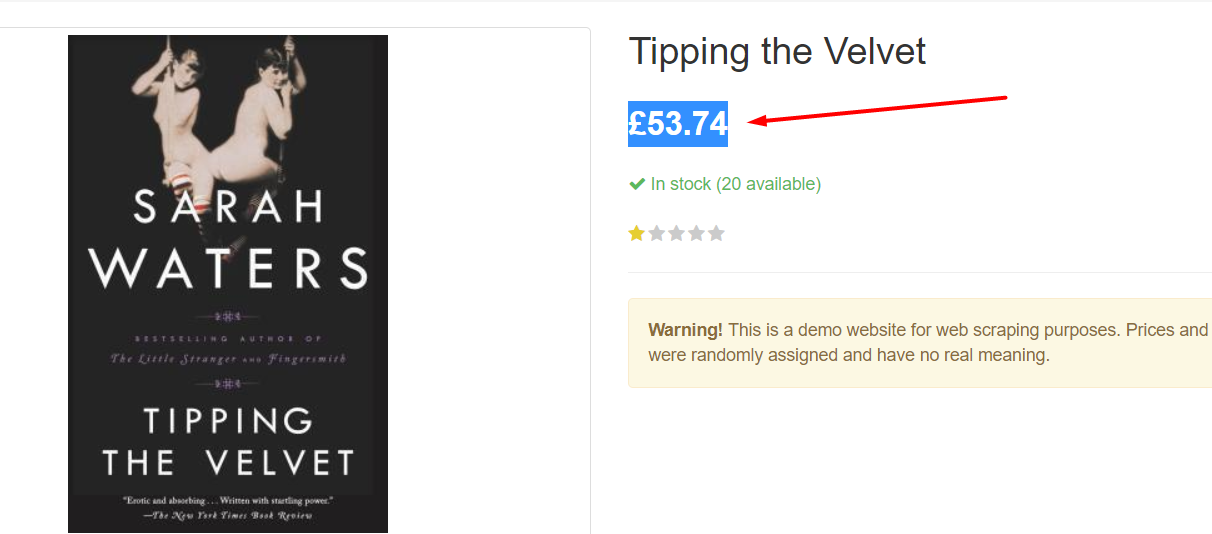

In [ ]:
# 1. make a request for the page containing the data

# 2. work out where in the html the price text is contained

# 3. find the element (programmatically) that contains the price text and extract it

# 4. Get the text from the element

# 5. Strip off the "£" to return the value


*Exercise 1:* Get a list of all links to the book categories available on the website. (EASY)

In [ ]:
# Get the homepage

# Parse into BS


In [ ]:
# Get the Category Link Tags - chained here as find returns a single element so find_all can be chained to it!

# Get the href attribute of the link and store in a list


*Exercise 2:* Get a list of all links to the books from your favourite category (eg: Philosophy) (MEDIUM)

Hint: (click Details to show)

<details>
If you select a page with more than 20 books, you might find it gets a bit tricky - as you need to navigate to the next page. We'll cover that in just a bit - but if you're up for the challenge try it yourself! Otherwise, here's a couple of categories that don't have that issue: Music, Travel, Classics, Philosophy, Religion, New Adult
</details>

In [ ]:
# Define the URL

# Get the HTML from the URL

# Parse the HTML into BS

# Get the article each book is contained within

# Get the 'h3' tag each link to the book title is is

# Get the href attribute for the link to the book title

# Print out the list of titles


In [ ]:
# Alternatively...

# Define the URL

# Get the HTML

# Parse the HTML into BS

# Find all of the links in the `ol` with a class of `row`

# Get all of the title attributes from links that have title attributes


### 2. More advanced notions

In [ ]:
## Let's pick the children's category for a more in depth analysis
## All the usual steps - establish the connection (request), verify our request and then parse the soup


In [ ]:
## Let's have a look at what is the very last href in our catalogue

# Create a list of all of the links


In [ ]:
## Turns out there are more books to scrape from this collection! There is a page 2 :o
## Luckily, there is a nice 'next' button associated with it. Let's inspect it and see if we could've spotted it somehow


In [ ]:
## Interestingly, it turns out we can get the end link to our page as 'page-2.html'
## The homepage is marked 'index.html', so that's a bit more complicated
## So: If we have multiple pages for the catalogues, it'll be page-{n}; if we don't it'll only be the index.html page
## Fun fact: IF we have multiple pages, the index.html page can also be called as the 'page-1.html'


In [ ]:

# Let's get that first page again so that we can visit all of the pages


# Find out how many pages in the category based on whether the "current" li exists
# See if the "current" li exists

    # Split the text in the "current" li

    # Set the number_of_pages

# List to collect the page numbers

# Loop through each of the pages in the children's category
    # Set the url to visit

    # Get the actual page through a request

    # Soupify the page

    # Get the "current" li text and add to the page_number_list

    # Append the Page X of Y statement to the list

    

In [ ]:
# Let's get all the books from our first page of 'Childrens', just like we've done before


# Find all of the links in the `ol` with a class of `row
# Get the link text from the ol



In [ ]:
# Let's combine visiting the page with getting the book data from it


# Find out how many pages in the category based on whether the "current" li exists

# See if the "current" li exists

    # Split the text in the "current" li

# List to collect the page numbers

# Loop through each of the pages in the children's category

    # Set the url to visit

    # Get the actual page through a request

    # Soupify the page

    # Get the books on the page and add their title to the book list




In [ ]:
## Let's pick a title at random from our list of books, and look at its page



In [ ]:
## Let the soup commence



In [ ]:
## Let's try to inspect the Product Information
## We notice a new tag: The 'tr' - containing two sub-tags: th and td
## Let's inspect it!



In [ ]:
## Looks like 'th' corresponds to the description feature, and 'td' is the value of the feature
## In other words: 'th' is the key, and 'td' is the value.
## Let's get the value for the UPC feature - which is the first one


In [ ]:
## Let's grab the key now as well


In [ ]:
## Using loops, can we extract the whole information about our product?
## We'll start with the keys



### 3. Practice time

_Exercise 0:_ Pick a different book from the Children's collection. Create a dataframe containing the Product Information type (the keys) as the headers, and the Product Information (the values) as the entries. Since it's 1 book only, you should get a dataframe with only 1 row, such as:

UPC         || Product type || ...

f7yba7s69as || Books        || ...

*Exercise 1:* Choose a category. Create a small dataframe containing each book's name and UPC from that category. (MEDIUM)
- Hint: You can get the names either from the main category page, or from each book's page. However, the UPC is only available on each book's page.


*Exercise 2:* Create a dataframe containing every book available on the website, as well as its assocciated category as 2 columns. (HARD)
- Hint: Don't forget to click on next pages where you need. This can be done in 1 single query.

_Exercise 3_: (FINAL EXERCISE) Scrape the website! We want a dataframe that has the following columns:

Book_name || Book_link || Category || Category_link || Book_stock_availability || Book_price || Book_UPC || Book_Tax || Book_number_of_reviews || Book_description

Notes: 

- The book name should be in full, not abbreviated

- The links should be working as they are (not just the end extension)

- Stock availability should contain the # of products available; Eg: In stock (8 available)

- Price and Tax should be consistent (either both have the £ sign, or neither do)

#### Resources

***HTML resources***


https://www.w3schools.com/tags/ref_httpmessages.asp -- HTML messages

https://www.w3schools.com/tags/default.asp -- HTML reference codes

https://developer.mozilla.org/en-US/docs/Learn/Getting_started_with_the_web/HTML_basics -- HTML Basics


***BeautifulSoup resources***

https://www.crummy.com/software/BeautifulSoup/bs4/doc/ -- BS4 documentation

https://www.dataquest.io/blog/web-scraping-python-using-beautiful-soup/ -- BS4 tutorial

***Other resources***

https://lxml.de/ -- LXML scraper

https://3.python-requests.org/ -- Python requests

https://scrapy.org/ -- Scrapy scraper

https://pypi.org/project/selenium/ -- Selenium